# Name: William Mensah
# ID: 2098061
# Assignment: Final Checkpoint

In [1]:
#imports
import sys
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import time, platform, os
from sklearn.metrics import roc_auc_score,roc_curve
import matplotlib.pyplot as plt

In [2]:
#read files
MAX_FPR = 0.01  #set at 1%

# Positive class (label 1) = phishing, negative class (label 0) = legitimate, in every dataset.

# Mendeley: CLASS_LABEL is already 1 = phishing, 0 = legitimate.
mendeley = pd.read_csv("Mendeley_dataset.csv")
mendeley["label"] = mendeley["CLASS_LABEL"].astype(int)
mendeley["row_id"] = "mendeley_" + mendeley["id"].astype(str)
mendeley = mendeley.drop(columns=["CLASS_LABEL", "id"])

# PhiUSIIL: label is 1 = legitimate, 0 = phishing, so flip it.
# utf-8-sig strips the byte-order mark at the start of the file.
phiusiil = pd.read_csv("PhiUSIIL_result.csv", encoding="utf-8-sig")
phiusiil["label"] = 1 - phiusiil["label"].astype(int)
phiusiil["row_id"] = "phiusiil_" + phiusiil.index.astype(str)   # no id column, use the row number

phiusiil = phiusiil.drop(columns=["FILENAME", "URL", "Domain", "TLD", "Title"])

# UCI: Result is -1 = phishing, 1 = legitimate, so map it to 1 / 0.
uci = pd.read_csv("UCILL_result.csv")
uci["label"] = (uci["Result"] == -1).astype(int)
uci["row_id"] = "uci_" + uci["id"].astype(str)
uci = uci.drop(columns=["Result", "id"])

datasets = {"mendeley": mendeley, "phiusiil": phiusiil, "uci": uci}

# Drop duplicates
for name, df in datasets.items():
    features = [c for c in df.columns if c not in ("label", "row_id")]
    before = len(df)

    # Exact duplicates
    df = df.drop_duplicates(subset=features + ["label"], keep="first")
    exact = before - len(df)

    # Conflicting duplicates (same features, different labels)
    conflicting = df.groupby(features)["label"].transform("nunique") > 1
    df = df[~conflicting].reset_index(drop=True)

    print(f"{name:<9} dropped {exact:>5} exact duplicates and {int(conflicting.sum()):>3} "
          f"conflicting rows ({before} -> {len(df)} rows)")
    datasets[name] = df

print()
for name, df in datasets.items():
    features = [c for c in df.columns if c not in ("label", "row_id")]
    print(f"{name:<9} rows={len(df):>7}  features={len(features):>3}  "
          f"phishing={int(df['label'].sum()):>6}  legitimate={int((df['label'] == 0).sum()):>6}  "
          f"unique row_ids={df['row_id'].is_unique}")

mendeley  dropped   419 exact duplicates and   0 conflicting rows (10000 -> 9581 rows)
phiusiil  dropped   808 exact duplicates and   0 conflicting rows (235795 -> 234987 rows)
uci       dropped  5206 exact duplicates and 128 conflicting rows (11055 -> 5721 rows)

mendeley  rows=   9581  features= 48  phishing=  4585  legitimate=  4996  unique row_ids=True
phiusiil  rows= 234987  features= 50  phishing=100137  legitimate=134850  unique row_ids=True
uci       rows=   5721  features= 30  phishing=  2955  legitimate=  2766  unique row_ids=True


In [3]:
#mapping
# Shared features: the same phishing signal, found in all three datasets, put on one scale.
# PhiUSIIL and Mendeley are converted to UCI's rules
# Binary features: 1 = present, 0 = absent.
# Band features:   0 = low, 1 = middle, 2 = high (UCI's 1 / 0 / -1).

def band(x, low, high):

    x = np.asarray(x, dtype=float)
    return np.select([x < low, x <= high], [0, 1], 2)

def uci_band(code):

    return code.map({1: 0, 0: 1, -1: 2}).to_numpy()

def flag(x):
    return np.asarray(x).astype(int)

SHARED_FEATURES = {
    "ip_in_url":        "the host is an IP address",
    "url_length_band":  "URL length: under 54 / 54 to 75 / over 75 characters",
    "at_symbol":        "the URL contains '@'",
    "double_slash":     "'//' appears after the protocol (a redirect inside the URL)",
    "dash_in_domain":   "the host name contains '-'",
    "subdomain_band":   "subdomain levels, counting www: 0-1 / 2 / 3 or more",
    "uses_https":       "the URL uses HTTPS",
    "ext_form_submit":  "a form submits to another domain or a blank action",
    "has_popup":        "the page opens a pop-up window",
    "has_iframe":       "the page uses an iframe or frame",
    "ext_anchor_band":  "links to other domains or nowhere: under 31% / 31-67% / over 67%",
}

p = datasets["phiusiil"]
p_text = pd.read_csv("PhiUSIIL_result.csv", encoding="utf-8-sig", usecols=["URL", "Domain"])
p_text.index = "phiusiil_" + p_text.index.astype(str)
p_text = p_text.loc[p["row_id"]]
p_links = p["NoOfExternalRef"] + p["NoOfEmptyRef"]
p_all_links = p_links + p["NoOfSelfRef"]
p_shared = {
    "ip_in_url":       flag(p["IsDomainIP"]),
    "url_length_band": band(p["URLLength"], 54, 75),
    "at_symbol":       flag(p_text["URL"].str.contains("@", regex=False)),
    "double_slash":    flag(p_text["URL"].str.rfind("//") > 7),
    "dash_in_domain":  flag(p_text["Domain"].str.contains("-", regex=False)),
    "subdomain_band":  band(p["NoOfSubDomain"], 2, 2),
    "uses_https":      flag(p["IsHTTPS"]),
    "ext_form_submit": flag(p["HasExternalFormSubmit"]),
    "has_popup":       flag(p["NoOfPopup"] > 0),
    "has_iframe":      flag(p["NoOfiFrame"] > 0),
    "ext_anchor_band": band(np.where(p_all_links > 0, p_links / p_all_links.where(p_all_links > 0, 1), 0),
                            0.31, 0.67),
}

m = datasets["mendeley"]
m_shared = {
    "ip_in_url":       flag(m["IpAddress"]),
    "url_length_band": band(m["UrlLength"], 54, 75),
    "at_symbol":       flag(m["AtSymbol"]),
    "double_slash":    flag(m["DoubleSlashInPath"]),
    "dash_in_domain":  flag(m["NumDashInHostname"] > 0),
    "subdomain_band":  band(m["SubdomainLevel"], 2, 2),
    "uses_https":      flag(m["NoHttps"] == 0),
    "ext_form_submit": flag((m["ExtFormAction"] == 1) | (m["AbnormalFormAction"] == 1)),
    "has_popup":       flag(m["PopUpWindow"]),
    "has_iframe":      flag(m["IframeOrFrame"]),
    "ext_anchor_band": band((m["PctExtHyperlinks"] + m["PctNullSelfRedirectHyperlinks"]).clip(upper=1),
                            0.31, 0.67),
}

u = datasets["uci"]
u_shared = {
    "ip_in_url":       flag(u["having_IP_Address"] == -1),
    "url_length_band": uci_band(u["URL_Length"]),
    "at_symbol":       flag(u["having_At_Symbol"] == -1),
    "double_slash":    flag(u["double_slash_redirecting"] == -1),
    "dash_in_domain":  flag(u["Prefix_Suffix"] == -1),
    "subdomain_band":  uci_band(u["having_Sub_Domain"]),
    "uses_https":      flag(u["SSLfinal_State"] != -1),   # -1 = no HTTPS; 0 and 1 are HTTPS
    "ext_form_submit": flag(u["SFH"] != 1),                # -1 = blank action, 0 = other domain
    "has_popup":       flag(u["popUpWidnow"] == -1),
    "has_iframe":      flag(u["Iframe"] == -1),
    "ext_anchor_band": uci_band(u["URL_of_Anchor"]),
}

shared = {}
for name, df, feats in [("phiusiil", p, p_shared), ("mendeley", m, m_shared), ("uci", u, u_shared)]:
    out = pd.DataFrame(feats, index=df.index)[list(SHARED_FEATURES)]
    out.insert(0, "row_id", df["row_id"].to_numpy())
    out["label"] = df["label"].to_numpy()
    assert out[list(SHARED_FEATURES)].notna().all().all(), f"{name}: unmapped values"
    shared[name] = out

check = pd.concat({name: df.groupby("label")[list(SHARED_FEATURES)].mean().T
                   for name, df in shared.items()}, axis=1).round(3)
check.columns = [f"{name} {'phish' if lab else 'legit'}" for name, lab in check.columns]
print(check.to_string())

                 phiusiil legit  phiusiil phish  mendeley legit  mendeley phish  uci legit  uci phish
ip_in_url                 0.000           0.006           0.000           0.034      0.383      0.489
url_length_band           0.000           0.311           1.120           0.818      1.562      1.655
at_symbol                 0.000           0.015           0.001           0.000      0.195      0.223
double_slash              0.000           0.009           0.000           0.002      0.157      0.131
dash_in_domain            0.075           0.313           0.050           0.123      0.747      1.000
subdomain_band            0.161           0.286           0.026           0.056      0.685      1.171
uses_https                1.000           0.489           0.004           0.017      0.914      0.378
ext_form_submit           0.074           0.004           0.217           0.094      0.732      0.929
has_popup                 0.096           0.005           0.010           0.000   

In [5]:
#split into train, validation, test
SEED = 42  # fixed

# 60% train, 20% validation, 20% test, stratified so each split keeps the dataset's class balance.
splits = {}   # splits[name] = {"train": df, "validation": df, "test": df}
for name, df in datasets.items():
    train, rest = train_test_split(df, test_size=0.40, stratify=df["label"], random_state=SEED)
    validation, test = train_test_split(rest, test_size=0.50, stratify=rest["label"],
                                        random_state=SEED)
    splits[name] = {"train": train, "validation": validation, "test": test}

split_df = pd.concat(
    [part[["row_id", "label"]].assign(dataset=name, split=split_name)
     for name, parts in splits.items() for split_name, part in parts.items()],
    ignore_index=True,
)[["row_id", "dataset", "split", "label"]]
split_df.to_csv("split.csv", index=False)

# Sanity checks: no row in two splits, and every kept row is in exactly one split.
assert split_df["row_id"].is_unique
assert len(split_df) == sum(len(df) for df in datasets.values())

summary = (split_df.groupby(["dataset", "split"], sort=False)["label"]
           .agg(rows="size", phishing="sum", phishing_pct="mean"))
summary["phishing_pct"] = (100 * summary["phishing_pct"]).round(2)
print(summary.to_string())
print(f"\nwrote split.csv ({len(split_df)} rows)")

                       rows  phishing  phishing_pct
dataset  split                                     
mendeley train         5748      2751         47.86
         validation    1916       917         47.86
         test          1917       917         47.84
phiusiil train       140992     60082         42.61
         validation   46997     20027         42.61
         test         46998     20028         42.61
uci      train         3432      1773         51.66
         validation    1144       591         51.66
         test          1145       591         51.62

wrote split.csv (250289 rows)


In [6]:
#train and threshold
def feature_cols(df):
    return [c for c in df.columns if c not in ("label", "row_id")]


def pick_threshold(y, scores, max_fpr):
    """Lowest threshold whose false-positive rate on (y, scores) is at most max_fpr.
    The lowest such threshold gives the highest recall within the FPR limit."""
    fpr, tpr, thr = roc_curve(y, scores)
    ok = (fpr <= max_fpr) & np.isfinite(thr)   #skip
    best = np.argmax(np.where(ok, tpr, -1))     # highest recall
    return float(thr[best])


models, thresholds = {}, {}
for name, parts in splits.items():
    X_cols = feature_cols(parts["train"])
    start = time.time()
    model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
    model.fit(parts["train"][X_cols], parts["train"]["label"])
    train_secs = time.time() - start

    y_val = parts["validation"]["label"].to_numpy()
    s_val = model.predict_proba(parts["validation"][X_cols])[:, 1]
    thr = pick_threshold(y_val, s_val, MAX_FPR)

    pred = (s_val >= thr).astype(int)
    val_fpr = pred[y_val == 0].mean()
    val_recall = pred[y_val == 1].mean()

    models[name], thresholds[name] = model, thr
    print(f"{name:<9} trained in {train_secs:5.1f}s  threshold={thr:.4f}  "
          f"validation: FPR={val_fpr:.4f}  recall={val_recall:.4f}  "
          f"AUROC={roc_auc_score(y_val, s_val):.4f}")

mendeley  trained in   0.2s  threshold=0.6600  validation: FPR=0.0090  recall=0.9618  AUROC=0.9984
phiusiil  trained in   3.4s  threshold=0.4050  validation: FPR=0.0000  recall=1.0000  AUROC=1.0000
uci       trained in   0.1s  threshold=0.7800  validation: FPR=0.0090  recall=0.8663  AUROC=0.9927


In [16]:
#leakage check
# A train row "duplicates" an evaluation row when every feature value matches (row_id is ignored).
# Such a row lets the model be scored on something it already saw in training.

SHARED_COLS = list(SHARED_FEATURES)

S = {name: {s: shared[name][shared[name]["row_id"].isin(part["row_id"])]
            for s, part in parts.items()}
     for name, parts in splits.items()}

def train_rows_duplicating(train, other):
    keys = other[SHARED_COLS + ["label"]].rename(columns={"label": "label_other"}).drop_duplicates()
    m = train.merge(keys, on=SHARED_COLS, how="inner")
    same = int((m["label"] == m["label_other"]).sum())
    return m["row_id"].nunique(), same, len(m) - same

rows = []
for model in S:   # model = training dataset
    train = S[model]["train"]
    for d in S:
        n, same, diff = train_rows_duplicating(train, S[d]["test"])
        rows.append({"model": model, "compared with": f"{d} test", "train rows duplicating": n,
                     "same label": same, "different label": diff})
    n, same, diff = train_rows_duplicating(train, S[model]["validation"])
    rows.append({"model": model, "compared with": f"{model} validation", "train rows duplicating": n,
                 "same label": same, "different label": diff})
print(pd.DataFrame(rows).to_string(index=False))
all_tests = pd.concat([S[d]["test"] for d in S], ignore_index=True)
for model in S:
    print(model, train_rows_duplicating(S[model]["train"], all_tests)[0])
print({n: shared[n][SHARED_COLS].drop_duplicates().shape[0] for n in shared})

all_tests = pd.concat([S[d]["test"] for d in S], ignore_index=True)

for model in S:
    n_any, _, _ = train_rows_duplicating(S[model]["train"], all_tests)
    print(model, "train rows duplicating a row in any test set:", n_any,
          f"({100 * n_any / len(S[model]['train']):.1f}% of {len(S[model]['train'])} train rows)")

   model       compared with  train rows duplicating  same label  different label
mendeley       mendeley test                    5605        5562             4713
mendeley       phiusiil test                    4949        2555             2414
mendeley            uci test                      52          34               29
mendeley mendeley validation                    5660        5607             4718
phiusiil       mendeley test                   84113       73692            31317
phiusiil       phiusiil test                  140711      140667            91747
phiusiil            uci test                   28189       20870             7327
phiusiil phiusiil validation                  140676      140641            90069
     uci       mendeley test                     242         219               29
     uci       phiusiil test                     460         282              277
     uci            uci test                    2779        2700              867
     uci      uc

**1(c) Leakage check.** I ran two checks.

1. **Exact duplicates on all features.** Before splitting, I removed duplicate rows inside each dataset (`#read files`): Mendeley 419, PhiUSIIL 808 and UCI 5,206 exact duplicates, plus 128 UCI rows with identical features but opposite labels. After the 60/20/20 split, I compared every validation and test row against the training rows on all features (`#leakage check`, above). **0 rows** in any validation or test split match a training row (0 of 1,917 Mendeley, 0 of 46,998 PhiUSIIL and 0 of 1,145 UCI test rows), so no test page was seen in training.
2. **Matches on the 11 shared features** (`#train on shared features`). Because these features are coarse, most test rows share their feature values with some training row: 99.9% for PhiUSIIL (46,938 of 46,998), 98.9% for Mendeley and 92.5% for UCI. Many of those matches carry the opposite label (6,191, 886 and 155 rows). These are different pages that look the same to the model, not copies, since check 1 found no full-feature duplicates. They limit how well any model on these features can separate the classes.

The checker flags three cells at or above 0.99. None of them comes from leakage:
- **phiusiil → phiusiil, precision 0.990.** The threshold was chosen on validation to keep the false-positive rate at or below 1%, so high precision is by design: 156 false positives against about 15,450 true positives. Recall is only 0.771, and check 1 found no shared rows.
- **phiusiil → mendeley, recall 0.996.** The false-positive rate is also 0.994, so the model flags almost every Mendeley page, and AUROC is 0.556, close to chance. That is a failure to transfer, not a sign of memorized test rows.
- **uci → mendeley, precision 1.000.** The UCI threshold (0.985) flags only 17 of 917 Mendeley phishing pages (recall 0.019) and no legitimate pages. Precision from 17 predictions is unstable, and the AUROC of 0.740 is far from perfect.

In the cross-dataset cells, training and test rows come from different datasets, so they cannot share row_ids. I could not check whether the same web page appears in two datasets, because Mendeley and UCI do not include the URL.

In [17]:
#train on shared features
# One random forest per dataset on the 11 shared features from #mapping
# train / validation / test rows as split.csv.
SHARED_COLS = list(SHARED_FEATURES)

shared_splits = {}   # shared_splits[name] = {"train": df, "validation": df, "test": df}
for name, df in shared.items():
    split_of = split_df[split_df["dataset"] == name].set_index("row_id")["split"]
    which = split_of.loc[df["row_id"]].to_numpy()
    shared_splits[name] = {s: df[which == s] for s in ["train", "validation", "test"]}

shared_models, shared_thresholds = {}, {}
for name, parts in shared_splits.items():
    model = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
    model.fit(parts["train"][SHARED_COLS], parts["train"]["label"])

    y_val = parts["validation"]["label"].to_numpy()
    s_val = model.predict_proba(parts["validation"][SHARED_COLS])[:, 1]
    thr = pick_threshold(y_val, s_val, MAX_FPR)
    pred = (s_val >= thr).astype(int)

    shared_models[name], shared_thresholds[name] = model, thr
    print(f"{name:<9} threshold={thr:.4f}  validation: FPR={pred[y_val == 0].mean():.4f}  "
          f"recall={pred[y_val == 1].mean():.4f}  AUROC={roc_auc_score(y_val, s_val):.4f}")


print()
for name, parts in shared_splits.items():
    matches, same, diff = train_duplicates(parts["train"], parts["test"], SHARED_COLS)
    print(f"{name:<9} test rows matching a train row on shared features: {len(matches)} of "
          f"{len(parts['test'])} ({100 * len(matches) / len(parts['test']):.1f}%), "
          f"{diff} with the opposite label")

phiusiil  threshold=0.8006  validation: FPR=0.0057  recall=0.7653  AUROC=0.9735
mendeley  threshold=0.9571  validation: FPR=0.0080  recall=0.4482  AUROC=0.8914
uci       threshold=0.9850  validation: FPR=0.0090  recall=0.6870  AUROC=0.9659

phiusiil  test rows matching a train row on shared features: 46938 of 46998 (99.9%), 6191 with the opposite label
mendeley  test rows matching a train row on shared features: 1895 of 1917 (98.9%), 886 with the opposite label
uci       test rows matching a train row on shared features: 1059 of 1145 (92.5%), 155 with the opposite label


In [9]:
#score test sets and write scores.csv
# value  = the training dataset (which shared-feature model made the score); baseline = phiusiil
# column = the test set the model is scored on
# Every model uses the same 11 shared features, so all 9 cells can be scored.
BASELINE = "phiusiil"
TRAIN_ORDER = [BASELINE] + [n for n in shared_splits if n != BASELINE]
TEST_ORDER = list(TRAIN_ORDER)

score_parts, grid = [], {}
for train_name in TRAIN_ORDER:
    model, thr = shared_models[train_name], shared_thresholds[train_name]
    for test_name in TEST_ORDER:
        test = shared_splits[test_name]["test"]
        s = model.predict_proba(test[SHARED_COLS])[:, 1]
        score_parts.append(pd.DataFrame({
            "row_id": test["row_id"].to_numpy(),
            "value": train_name,
            "column": test_name,
            "label": test["label"].to_numpy(),
            "score": s,
            "threshold": thr,
        }))
        pred = (s >= thr).astype(int)
        y = test["label"].to_numpy()
        grid[(train_name, test_name)] = (f"recall={pred[y == 1].mean():.3f} "
                                         f"FPR={pred[y == 0].mean():.3f} "
                                         f"AUROC={roc_auc_score(y, s):.3f}")

scores_df = pd.concat(score_parts, ignore_index=True)
scores_df.to_csv("scores.csv", index=False)

# Every scored row must be a test row in split.csv with the same label.
test_labels = split_df[split_df["split"] == "test"].set_index("row_id")["label"]
assert scores_df["row_id"].isin(test_labels.index).all()
assert (scores_df["label"].to_numpy() == test_labels.loc[scores_df["row_id"]].to_numpy()).all()

print("rows = value (training dataset), columns = test set\n")
print(pd.DataFrame({t: [grid[(v, t)] for v in TRAIN_ORDER] for t in TEST_ORDER},
                   index=TRAIN_ORDER).to_string())
print(f"\nwrote scores.csv ({len(scores_df)} rows, "
      f"{scores_df.groupby(['value', 'column']).ngroups} scored cells)")

rows = value (training dataset), columns = test set

                                    phiusiil                            mendeley                                 uci
phiusiil  recall=0.771 FPR=0.006 AUROC=0.974  recall=0.996 FPR=0.994 AUROC=0.556  recall=0.932 FPR=0.807 AUROC=0.627
mendeley  recall=0.317 FPR=0.068 AUROC=0.825  recall=0.418 FPR=0.009 AUROC=0.907  recall=0.443 FPR=0.123 AUROC=0.735
uci       recall=0.026 FPR=0.001 AUROC=0.709  recall=0.019 FPR=0.000 AUROC=0.740  recall=0.643 FPR=0.007 AUROC=0.965

wrote scores.csv (150180 rows, 9 scored cells)


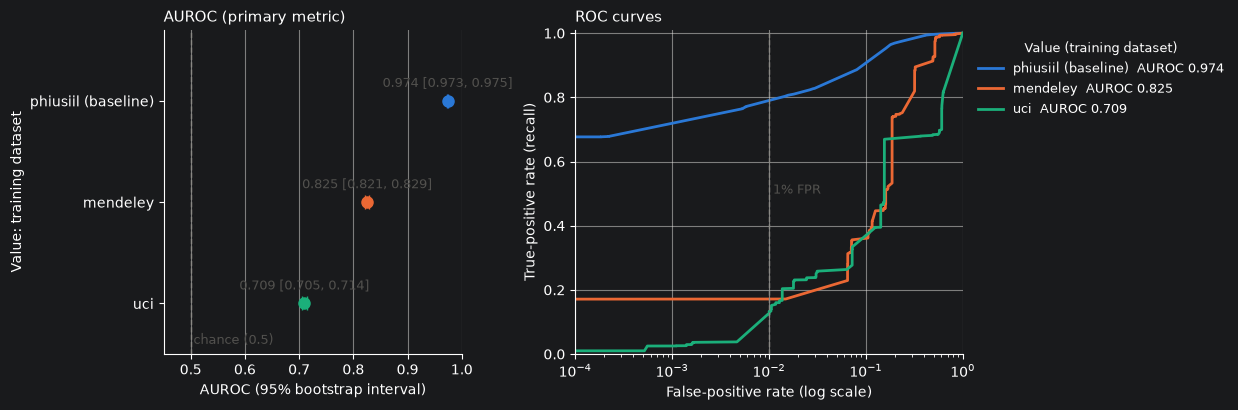

Column: phiusiil test set, 46998 test rows, 42.61% positive (phishing)
           AUROC  ci_low  ci_high  diff_from_baseline
value                                                
phiusiil  0.9737  0.9725   0.9748              0.0000
mendeley  0.8252  0.8213   0.8286             -0.1485
uci       0.7095  0.7048   0.7143             -0.2642


In [11]:
#Figure
# One column (the PhiUSIIL test set), every value (training dataset), baseline first.
# Left: AUROC (primary metric) per value, with 95% bootstrap interval bars made exactly as
#       check_final_checkpoint.py makes them (same seed, same resamples, same percentiles).
# Right: ROC curves with a log false-positive axis (AUROC is the area under these curves).
import zlib
from sklearn.metrics import roc_curve

FIG_COLUMN = "phiusiil"
COLORS = {"phiusiil": "#2a78d6", "mendeley": "#eb6834", "uci": "#1baf7a"}   # fixed per value

def checker_auroc_ci(g):
    """AUROC and its 95% interval, resampled the way the checker does."""
    g = g.sort_values("row_id", kind="mergesort")
    y = g["label"].to_numpy()
    s = g["score"].to_numpy(dtype=float)
    val, col = str(g["value"].iloc[0]), str(g["column"].iloc[0])
    rng = np.random.default_rng([zlib.crc32(val.encode()), zlib.crc32(col.encode())])
    reps = 200 if len(y) > 100_000 else 1000
    draws = []
    for _ in range(reps):
        idx = rng.integers(0, len(y), len(y))
        if 0 < y[idx].sum() < len(idx):                 # AUROC needs both classes
            draws.append(roc_auc_score(y[idx], s[idx]))
    return roc_auc_score(y, s), np.percentile(draws, 2.5), np.percentile(draws, 97.5)

col_df = scores_df[scores_df["column"] == FIG_COLUMN]
fig, (ax_a, ax_roc) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})

fig_rows = []
for i, val in enumerate(TRAIN_ORDER):
    g = col_df[col_df["value"] == val]
    auc, lo, hi = checker_auroc_ci(g)
    fig_rows.append({"value": val, "AUROC": auc, "ci_low": lo, "ci_high": hi,
                     "diff_from_baseline": np.nan})
    label = f"{val} (baseline)" if val == BASELINE else val

    ax_a.errorbar(auc, i, xerr=[[auc - lo], [hi - auc]], fmt="o", ms=8, color=COLORS[val],
                  ecolor=COLORS[val], elinewidth=2, capsize=5)
    ax_a.annotate(f"{auc:.3f} [{lo:.3f}, {hi:.3f}]", (auc, i), xytext=(0, 10),
                  textcoords="offset points", ha="center", fontsize=9, color="#52514e")

    f, t, _ = roc_curve(g["label"].to_numpy(), g["score"].to_numpy())
    ax_roc.plot(f, t, color=COLORS[val], lw=2, label=f"{label}  AUROC {auc:.3f}")

ax_a.axvline(0.5, color="#8a8984", lw=1, ls="--")
ax_a.text(0.505, len(TRAIN_ORDER) - 0.6, "chance (0.5)", fontsize=9, color="#52514e")
ax_a.set_yticks(range(len(TRAIN_ORDER)))
ax_a.set_yticklabels([f"{v} (baseline)" if v == BASELINE else v for v in TRAIN_ORDER])
ax_a.set_xlim(0.45, 1)
ax_a.set_ylim(len(TRAIN_ORDER) - 0.5, -0.7)
ax_a.set_xlabel("AUROC (95% bootstrap interval)")
ax_a.set_ylabel("Value: training dataset")
ax_a.set_title("AUROC (primary metric)", loc="left", fontsize=11)
ax_a.grid(axis="x", color="#e4e3df", lw=0.8)

ax_roc.set_xscale("log")
ax_roc.set_xlim(1e-4, 1)
ax_roc.set_ylim(0, 1.01)
ax_roc.axvline(MAX_FPR, color="#8a8984", lw=1, ls="--")
ax_roc.text(MAX_FPR * 1.1, 0.50, "1% FPR", fontsize=9, color="#52514e")
ax_roc.set_xlabel("False-positive rate (log scale)")
ax_roc.set_ylabel("True-positive rate (recall)")
ax_roc.set_title("ROC curves", loc="left", fontsize=11)
ax_roc.grid(color="#e4e3df", lw=0.8)
ax_roc.legend(title="Value (training dataset)", fontsize=9, title_fontsize=9, loc="upper left",
              bbox_to_anchor=(1.01, 1), frameon=False)

for ax in (ax_a, ax_roc):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

n_rows = len(col_df) // len(TRAIN_ORDER)
pct_pos = 100 * col_df[col_df["value"] == BASELINE]["label"].mean()
fig.tight_layout()
fig.savefig("figure_phiusiil_column.png", dpi=200, bbox_inches="tight")
plt.show()

fig_table = pd.DataFrame(fig_rows).set_index("value")
fig_table["diff_from_baseline"] = fig_table["AUROC"] - fig_table.loc[BASELINE, "AUROC"]
print(f"Column: {FIG_COLUMN} test set, {n_rows} test rows, {pct_pos:.2f}% positive (phishing)")
print(fig_table.round(4).to_string())

**Figure 1.** Column: **PhiUSIIL test set** (46,998 test rows, 42.61% positive = phishing). Values shown: random forests trained on **PhiUSIIL (baseline)**, **Mendeley** and **UCI**, all on the same 11 shared features. Left: AUROC (primary metric) with 95% bootstrap interval bars (1,000 resamples, made the same way as `check_final_checkpoint.py`); the dashed line marks chance (0.5). Right: ROC curves with a log false-positive axis; the dashed line marks the 1% false-positive rate.

AUROC falls from 0.974 [0.973, 0.975] for the PhiUSIIL-trained baseline to 0.825 [0.821, 0.829] when the model is trained on Mendeley (−0.149) and 0.709 [0.705, 0.714] when trained on UCI (−0.264), with intervals that do not overlap, so a model trained on another dataset ranks PhiUSIIL's phishing pages above its legitimate pages much less reliably, even when the features are mapped to the same scale.

In [ ]:
#4. ERROR ANALYSIS

ERR_VALUE, ERR_COLUMN, N_PER_TYPE = BASELINE, "phiusiil", 10

cell = scores_df[(scores_df["value"] == ERR_VALUE) & (scores_df["column"] == ERR_COLUMN)].copy()
cell["pred"] = (cell["score"] >= cell["threshold"]).astype(int)
assert cell["label"].nunique() == 2, "the cell must have both classes"

fp_all = cell[(cell["pred"] == 1) & (cell["label"] == 0)]
fn_all = cell[(cell["pred"] == 0) & (cell["label"] == 1)]

if len(fp_all) + len(fn_all) == 0:
    print(f"No errors: value {ERR_VALUE}, column {ERR_COLUMN} has no misclassified rows.")
    error_sample = cell.iloc[0:0]
else:
    fp_s = fp_all.sample(n=min(N_PER_TYPE, len(fp_all)), random_state=SEED)
    fn_s = fn_all.sample(n=min(N_PER_TYPE, len(fn_all)), random_state=SEED)
    error_sample = pd.concat([fp_s.assign(error="false positive"),
                              fn_s.assign(error="false negative")])

print(f"value={ERR_VALUE}  column={ERR_COLUMN}  seed={SEED}  threshold={cell['threshold'].iloc[0]:.4f}")
print(f"test rows={len(cell)}  available: {len(fp_all)} false positives, {len(fn_all)} false negatives")
print(f"sampled: {(error_sample['error'] == 'false positive').sum()} false positives, "
      f"{(error_sample['error'] == 'false negative').sum()} false negatives\n")

if "shared_splits" in globals():
    feats = shared_splits[ERR_COLUMN]["test"][["row_id"] + SHARED_COLS]
    error_sample = error_sample.merge(feats, on="row_id", how="left")
show = ["error", "row_id", "label", "score"] + [c for c in SHARED_COLS if c in error_sample] \
       if "SHARED_COLS" in globals() else ["error", "row_id", "label", "score"]
print(error_sample[show].round(4).to_string(index=False))

In [ ]:
#4. categories

HOSTING = ("square.site", "firebaseapp.com", "github.io", "web.core.windows.net")   # free page hosts
SHORTENERS = ("shorturl.at", "s.id")                                                # link shorteners

CATEGORY_RULES = [   # (name, error type, one-sentence rule, test on one row)
    ("dash domain, external links",  "false positive",
     "A legitimate page whose host name contains '-' and whose links mostly (over 67%) go to other "
     "domains or nowhere, the pattern the model learned from phishing.",
     lambda r: r["dash_in_domain"] == 1 and r["ext_anchor_band"] == 2),
    ("free hosting subdomain",       "false negative",
     "A phishing page on a subdomain of a free hosting platform (Square, Firebase, GitHub Pages, "
     "Azure), so the domain itself looks trustworthy.",
     lambda r: r["Domain"].endswith(HOSTING)),
    ("URL shortener",                "false negative",
     "A phishing link behind a URL shortener, so the URL features describe the shortener, not "
     "the page it leads to.",
     lambda r: r["Domain"] in SHORTENERS),
    ("clean URL on own domain",      "false negative",
     "A phishing page on its own HTTPS domain with a URL under 54 characters, no IP address, no "
     "'@' and at most one subdomain, so every URL rule reads as legitimate.",
     lambda r: r["uses_https"] == 1 and r["url_length_band"] == 0 and r["ip_in_url"] == 0
               and r["at_symbol"] == 0 and r["subdomain_band"] == 0),
]

def categorize(r):
    for name, kind, _, test in CATEGORY_RULES:
        if r["error"] == kind and test(r):
            return name
    return "other"

cat_rows = error_sample.merge(p_text.rename_axis("row_id").reset_index(), on="row_id", how="left")
cat_rows["category"] = cat_rows.apply(categorize, axis=1)
assert (cat_rows["category"] == "other").sum() <= 5, "a catch-all may hold at most 5 rows"

print(cat_rows[["error", "row_id", "Domain", "category"]].to_string(index=False))

category_table = pd.DataFrame([{
    "category": name,
    "rule": rule,
    "false positives": int(((cat_rows["category"] == name) & (cat_rows["error"] == "false positive")).sum()),
    "false negatives": int(((cat_rows["category"] == name) & (cat_rows["error"] == "false negative")).sum()),
    "example row_id": cat_rows.loc[cat_rows["category"] == name, "row_id"].iloc[0]
                      if (cat_rows["category"] == name).any() else "",
} for name, _, rule, _ in CATEGORY_RULES])
print()
print(category_table.drop(columns="rule").to_string(index=False))

fp_feats = fp_all.merge(shared_splits[ERR_COLUMN]["test"][["row_id"] + SHARED_COLS], on="row_id")
covered = ((fp_feats["dash_in_domain"] == 1) & (fp_feats["ext_anchor_band"] == 2)).sum()
print(f"\n'dash domain, external links' covers {covered} of all {len(fp_feats)} false positives in the cell")

# errors.csv for the checker
errors_df = cat_rows[["row_id"]].assign(value=ERR_VALUE, column=ERR_COLUMN,
                                        category=cat_rows["category"].to_numpy())
errors_df.to_csv("errors.csv", index=False)
print(f"wrote errors.csv ({len(errors_df)} rows)")

In [ ]:
#time
# Compute: total minutes for the remaining runs, from measured training times.
# One "run" = training the 3 shared-feature random forests (one per training dataset), exactly as
TIMING_REPEATS = 3
N_EXTRA_SEEDS = 5
REMAINING_RUNS = {"final re-run (seed 42)": 1, f"extra seeds ({N_EXTRA_SEEDS})": N_EXTRA_SEEDS}

train_secs = {}
for name, parts in shared_splits.items():
    times = []
    for _ in range(TIMING_REPEATS):
        start = time.time()
        RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(
            parts["train"][SHARED_COLS], parts["train"]["label"])
        times.append(time.time() - start)
    train_secs[name] = float(np.median(times))
    print(f"{name:<9} {len(parts['train']):>7} train rows  median training time {train_secs[name]:.2f}s")

secs_per_run = sum(train_secs.values())
print(f"\none run (3 models): {secs_per_run:.2f}s   machine: {platform.machine()}, {os.cpu_count()} CPUs\n")

total_secs = 0.0
for what, runs in REMAINING_RUNS.items():
    secs = runs * secs_per_run
    total_secs += secs
    print(f"{what:<24} {runs:>2} run(s) x 3 models = {runs * 3:>3} models  {secs:7.1f}s  {secs / 60:6.2f} min")
print(f"{'total remaining':<24} {sum(REMAINING_RUNS.values()):>2} run(s) x 3 models = "
      f"{3 * sum(REMAINING_RUNS.values()):>3} models  {total_secs:7.1f}s  {total_secs / 60:6.2f} min")